# マルチバンド走査線補間（MSU-MR Ch1/Ch2/Ch4 × ひまわり8号事前学習 × PyTorch MPS）

METEOR-M2 の LRPT データでは、可視（`MSU-MR-1`）・近赤外（`MSU-MR-2`）・赤外（`MSU-MR-4`）が別々のパケット（APID）で送信されるため、**「Ch1 は欠損したが、同じ場所の Ch2 や Ch4 は無傷」** という領域が大量に存在します。

本ノートブックでは、単一の合成画像ではなく **3 バンド画像 + 3 バンド生存マスクの 6 チャンネル入力** を用いた **マルチバンド U-Net** を Apple Silicon **MPS** 上で構築し、生き残っている他バンドの雲・地形構造をガイドにして欠損バンドを復元します。

## 1. 理論と目的の確認

### 実測データが示す「マルチバンド救済ポテンシャル」
LRPT の最小ブロック単位（`8×8` MCU）で実測 5 パスを調査すると、以下のように **22%〜55% もの領域で「一部バンドだけが欠損し、別バンドが生き残っている」** ことが分かります。

| 実測パス ID | 全Ch生存 | **一部Chのみ生存（他Chから復元可能）** | 全Ch同時欠損 |
| :--- | :---: | :---: | :---: |
| `METEOR-M2 3_20261026_003009` | 28.6% | **22.7%** | 48.7% |
| `METEOR-M2 3_20261027_000649` | 18.5% | **24.1%** | 57.4% |
| `METEOR-M2 3_20261103_004421` | 41.5% | **50.1%** | 8.5% |
| `METEOR-M2 3_20261025_005344` | 20.0% | **55.7%** | 24.3% |
| `METEOR-M2 4_20261025_181705` | 77.9% | **22.1%** | **0.0%** |

### Masked Loss と ひまわり8号 3バンド事前学習
- **Masked Loss**: 元画像にもともと含まれる欠損黒帯（`clean <= 0.02`）を `gt_valid = 0` として学習・評価から除外し、**もともと生きていた領域に人工マスクを被せた画素（`hole = gt_valid * (1 - syn_mask)`）** だけで L1 + エッジ連続性損失を計算します。これにより欠損混じりの実測パスも安全に Fine-tuning へ投入できます。
- **ひまわり8号 3バンド対応（`PubAccount/Himawari-Japen`）**:
  - `Ch1 (可視)` $\leftrightarrow$ `albedo_03` (0.64 μm)
  - `Ch2 (近赤外)` $\leftrightarrow$ `albedo_04` (0.86 μm)
  - `Ch4 (赤外)` $\leftrightarrow$ `tbb_07`（3.9 μm 輝度温度を `clip((310 - T)/70, 0, 1)` で低温の雲＝高輝度となるよう反転正規化）

## 2. データ準備（ひまわり8号 3バンドキャッシュ ＋ METEOR 実測3バンド抽出）

未知評価のリークを防ぐため、`METEOR-M2 3_20261026_003009` の `160 <= y < 225` にある **100% 3バンド完全無欠損パッチ（48 枚）** を Validation 専用にホールドアウトし、その座標と 1 ピクセルも重ならない領域（`y + 64 <= 160` または `y >= 288`）および他パスを Fine-tuning に用います。

ひまわり3バンド事前学習パッチ: 2247 枚
METEOR 実測 FT パッチ (重複なし): 563 枚
METEOR 未知 Val パッチ (100% 無欠損): 48 枚


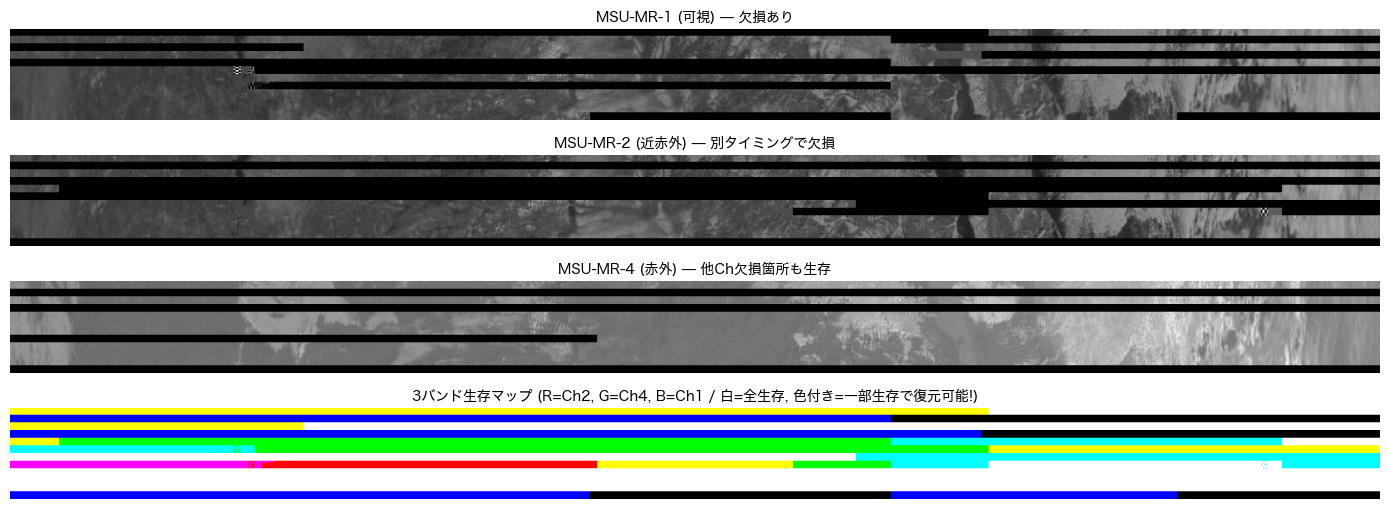

In [1]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

from pathlib import Path
import h5py
import numpy as np
from PIL import Image
from huggingface_hub import hf_hub_download

REPO_ROOT = Path.cwd().resolve()
while not (REPO_ROOT / "pyproject.toml").exists() and REPO_ROOT != REPO_ROOT.parent:
    REPO_ROOT = REPO_ROOT.parent

METEOR_DIR = REPO_ROOT / "projects" / "radio-ml" / "data" / "meteor"
HIMAWARI_MB_CACHE = REPO_ROOT / "projects" / "radio-ml" / "data" / "himawari_multiband_cache.npz"

HIMAWARI_FILES = [
    "201801/15/03/NC_H08_20180115_0300_r14_FLDK.02701_02601.nc",
    "201804/15/03/NC_H08_20180415_0300_r14_FLDK.02701_02601.nc",
    "201807/15/03/NC_H08_20180715_0300_r14_FLDK.02701_02601.nc",
    "201810/15/03/NC_H08_20181015_0300_r14_FLDK.02701_02601.nc",
]

def load_himawari_3band(nc_relpath: str, downsample: int = 2) -> np.ndarray:
    local_nc = hf_hub_download("PubAccount/Himawari-Japen", nc_relpath, repo_type="dataset")
    with h5py.File(local_nc, "r") as f:
        def _read_scaled(key: str) -> np.ndarray:
            ds = f[key]
            raw = ds[::downsample, ::downsample]
            scale = float(np.atleast_1d(ds.attrs.get("scale_factor", 1.0))[0])
            offset = float(np.atleast_1d(ds.attrs.get("add_offset", 0.0))[0])
            return np.where(raw > -30000, raw.astype(np.float32) * scale + offset, np.nan)

        alb3 = np.nan_to_num(_read_scaled("albedo_03"), nan=0.0)
        alb4 = np.nan_to_num(_read_scaled("albedo_04"), nan=0.0)
        tbb7 = _read_scaled("tbb_07")

    ch1 = np.power(np.clip(alb3, 0.0, 1.0), 1.0 / 2.2)
    ch2 = np.power(np.clip(alb4, 0.0, 1.0), 1.0 / 2.2)
    # 低温の雲ほど明るくなるよう反転正規化 (310K -> 0, 240K -> 1)
    ch4 = np.nan_to_num(np.clip((310.0 - tbb7) / 70.0, 0.0, 1.0), nan=0.0)
    return np.stack([ch1, ch2, ch4], axis=-1).astype(np.float32)

if HIMAWARI_MB_CACHE.exists():
    cached = np.load(HIMAWARI_MB_CACHE)
    himawari_scenes = [cached[f"scene_{i}"] for i in range(len(HIMAWARI_FILES))]
else:
    HIMAWARI_MB_CACHE.parent.mkdir(parents=True, exist_ok=True)
    himawari_scenes = [load_himawari_3band(rel) for rel in HIMAWARI_FILES]
    np.savez_compressed(HIMAWARI_MB_CACHE, **{f"scene_{i}": s for i, s in enumerate(himawari_scenes)})

# ひまわり事前学習パッチ (N, 3, 64, 64)
hima_list = []
for arr in himawari_scenes:
    h, w, _ = arr.shape
    for y in range(0, h - 64 + 1, 48):
        for x in range(0, w - 64 + 1, 48):
            crop = arr[y:y + 64, x:x + 64]
            if (crop > 0.02).all(axis=2).mean() == 1.0 and crop.std() > 0.02:
                hima_list.append(crop.transpose(2, 0, 1))
himawari_patches = np.stack(hima_list).astype(np.float32)

def load_meteor_3band(pass_id: str) -> np.ndarray:
    pdir = METEOR_DIR / pass_id
    c1 = np.asarray(Image.open(pdir / "MSU-MR-1.png").convert("L"), dtype=np.float32) / 255.0
    c2 = np.asarray(Image.open(pdir / "MSU-MR-2.png").convert("L"), dtype=np.float32) / 255.0
    c4 = np.asarray(Image.open(pdir / "MSU-MR-4.png").convert("L"), dtype=np.float32) / 255.0
    return np.stack([c1, c2, c4], axis=-1).astype(np.float32)

arr_1026 = load_meteor_3band("METEOR-M2 3_20261026_003009")
all_v_1026 = (arr_1026 > 0.02).all(axis=2)

# 1. Holdout Val: 10/26 の y in [160, 225) から 100% 3バンド無欠損パッチを抽出
val_list = []
for y in range(160, 225, 16):
    for x in range(0, arr_1026.shape[1] - 64 + 1, 32):
        if all_v_1026[y:y + 64, x:x + 64].mean() == 1.0:
            val_list.append(arr_1026[y:y + 64, x:x + 64].transpose(2, 0, 1))
meteor_val_patches = np.stack(val_list).astype(np.float32)

# 2. Fine-tuning Train: ホールドアウト帯と重ならない 10/26 領域 + 別日の実測パス
ft_list = []
for y in range(0, arr_1026.shape[0] - 64 + 1, 24):
    if not (y + 64 <= 160 or y >= 288):
        continue
    for x in range(0, arr_1026.shape[1] - 64 + 1, 32):
        if all_v_1026[y:y + 64, x:x + 64].mean() >= 0.40:
            ft_list.append(arr_1026[y:y + 64, x:x + 64].transpose(2, 0, 1))

for other_pid in ["METEOR-M2 3_20261027_000649", "METEOR-M2 3_20261103_004421", "METEOR-M2 4_20261025_181705"]:
    arr_o = load_meteor_3band(other_pid)
    av_o = (arr_o > 0.02).mean(axis=2)
    for y in range(0, arr_o.shape[0] - 64 + 1, 16):
        for x in range(0, arr_o.shape[1] - 64 + 1, 32):
            if av_o[y:y + 64, x:x + 64].mean() >= 0.50:
                ft_list.append(arr_o[y:y + 64, x:x + 64].transpose(2, 0, 1))

meteor_ft_patches = np.stack(ft_list).astype(np.float32)
print(f"ひまわり3バンド事前学習パッチ: {len(himawari_patches)} 枚")
print(f"METEOR 実測 FT パッチ (重複なし): {len(meteor_ft_patches)} 枚")
print(f"METEOR 未知 Val パッチ (100% 無欠損): {len(meteor_val_patches)} 枚")

# --- 実測パス (20261103_004421) におけるバンド独立欠損の可視化 ---
arr_1103 = load_meteor_3band("METEOR-M2 3_20261103_004421")
surv_map = np.stack([
    (arr_1103[..., 1] > 0.02).astype(np.float32),  # R = Ch2 生存
    (arr_1103[..., 2] > 0.02).astype(np.float32),  # G = Ch4 生存
    (arr_1103[..., 0] > 0.02).astype(np.float32),  # B = Ch1 生存
], axis=-1)

fig, axes = plt.subplots(4, 1, figsize=(14, 5.2))
titles = [
    "MSU-MR-1 (可視) — 欠損あり",
    "MSU-MR-2 (近赤外) — 別タイミングで欠損",
    "MSU-MR-4 (赤外) — 他Ch欠損箇所も生存",
    "3バンド生存マップ (R=Ch2, G=Ch4, B=Ch1 / 白=全生存, 色付き=一部生存で復元可能!)",
]
imgs = [arr_1103[..., 0], arr_1103[..., 1], arr_1103[..., 2], surv_map]
for ax, im_show, title in zip(axes, imgs, titles):
    ax.imshow(im_show, cmap="gray" if im_show.ndim == 2 else None, aspect="auto")
    ax.set_title(title, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. 可視化と考察：単一バンド補間 vs マルチバンド補間（6ch 入力）の定量比較

同じ `MultiBandUNet (in_ch=6, out_ch=3)` を使って、以下 3 通りの条件を同一の Val マスクで比較します。
1. **事前学習なし（METEOR Masked-Loss FT のみ）**
2. **ひまわり 3 バンド事前学習 + METEOR Masked-Loss FT**
3. **他Ch参照なしベースライン（単一バンド相当）**: 推論時に欠損バンド以外のチャンネル（値とマスク）をゼロで遮断し、上下の走査線コンテキストだけで補間した場合の誤差

使用デバイス: mps


Val Hole L1 比較 (未知領域 10/26 48枚):
  1. 単一バンド補間 (他Ch参照遮断): 0.0394
  2. マルチバンド (事前学習なし)   : 0.0381
  3. マルチバンド (ひまわり+FT)    : 0.0270


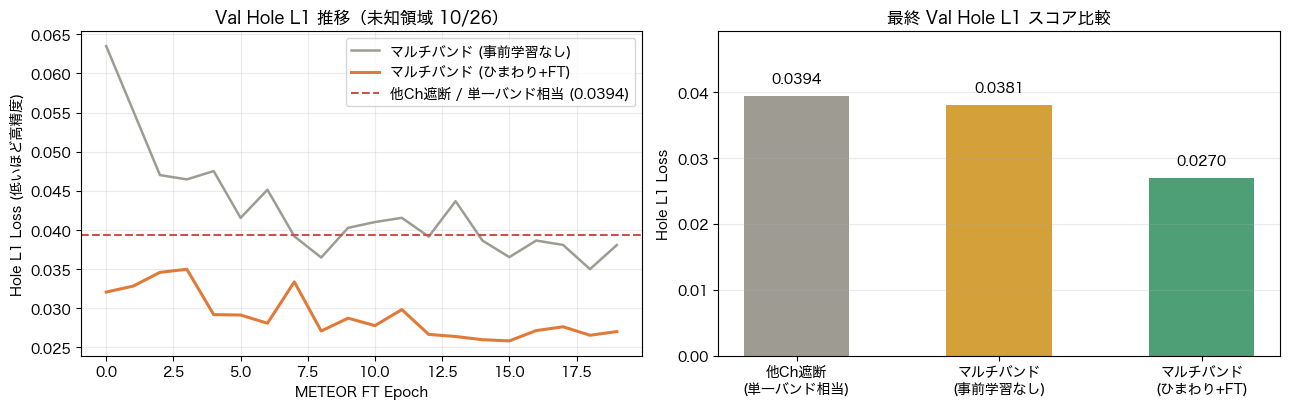

In [2]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("使用デバイス:", device)

class IndependentBandStripeDataset(Dataset):
    def __init__(self, patches: np.ndarray, fixed_seed: int | None = None):
        self.patches = torch.from_numpy(patches)
        self.fixed_seed = fixed_seed

    def __len__(self):
        return len(self.patches)

    def __getitem__(self, idx):
        clean = self.patches[idx]
        c, h, w = clean.shape
        gt_valid = (clean > 0.02).float()
        rng = np.random.default_rng(self.fixed_seed + idx) if self.fixed_seed is not None else np.random.default_rng()
        syn_mask = torch.ones((c, h, w), dtype=torch.float32)

        # バンドごとに独立に水平欠損を入れる（常に最低1バンドは残るケースを多く含める）
        drop_bands = rng.choice(c, size=int(rng.integers(1, c + 1)), replace=False)
        for b in drop_bands:
            n_stripes = int(rng.integers(1, 3))
            for _ in range(n_stripes):
                sh = int(rng.integers(6, 15))
                y0 = int(rng.integers(4, h - sh - 4))
                syn_mask[int(b), y0:y0 + sh, :] = 0.0

        obs_mask = gt_valid * syn_mask
        corrupted = clean * obs_mask
        hole_mask = gt_valid * (1.0 - syn_mask)
        return corrupted, obs_mask, hole_mask, clean

class MultiBandUNet(nn.Module):
    def __init__(self, base=32):
        super().__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(6, base, 3, padding=1), nn.ReLU(), nn.Conv2d(base, base, 3, padding=1), nn.ReLU())
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = nn.Sequential(nn.Conv2d(base, base * 2, 3, padding=1), nn.ReLU(), nn.Conv2d(base * 2, base * 2, 3, padding=1), nn.ReLU())
        self.pool2 = nn.MaxPool2d(2)
        self.bottleneck = nn.Sequential(nn.Conv2d(base * 2, base * 4, 3, padding=1), nn.ReLU(), nn.Conv2d(base * 4, base * 4, 3, padding=1), nn.ReLU())
        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = nn.Sequential(nn.Conv2d(base * 4, base * 2, 3, padding=1), nn.ReLU(), nn.Conv2d(base * 2, base * 2, 3, padding=1), nn.ReLU())
        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = nn.Sequential(nn.Conv2d(base * 2, base, 3, padding=1), nn.ReLU(), nn.Conv2d(base, base, 3, padding=1), nn.ReLU())
        self.out_conv = nn.Conv2d(base, 3, 1)

    def forward(self, corrupted, obs_mask):
        x = torch.cat([corrupted, obs_mask], dim=1)
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        b = self.bottleneck(self.pool2(e2))
        d2 = self.dec2(torch.cat([self.up2(b), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        pred = torch.sigmoid(self.out_conv(d1))
        return corrupted * obs_mask + pred * (1.0 - obs_mask)

def masked_hole_edge_loss(pred, clean, hole_mask, obs_mask):
    l1 = (torch.abs(pred - clean) * hole_mask).sum() / (hole_mask.sum() + 1e-6)
    valid_both = ((hole_mask + obs_mask) > 0.5).float()
    dy_m = valid_both[:, :, 1:, :] * valid_both[:, :, :-1, :]
    dx_m = valid_both[:, :, :, 1:] * valid_both[:, :, :, :-1]
    dy = (torch.abs((pred[:, :, 1:, :] - pred[:, :, :-1, :]) - (clean[:, :, 1:, :] - clean[:, :, :-1, :])) * dy_m).sum() / (dy_m.sum() + 1e-6)
    dx = (torch.abs((pred[:, :, :, 1:] - pred[:, :, :, :-1]) - (clean[:, :, :, 1:] - clean[:, :, :, :-1])) * dx_m).sum() / (dx_m.sum() + 1e-6)
    return l1 + 0.4 * (dy + dx) * 0.5, l1

def eval_multiband(model, loader, isolate_bands: bool = False):
    model.eval()
    hole_abs_sum, hole_px_sum = 0.0, 0.0
    with torch.no_grad():
        for corr, omask, hmask, cln in loader:
            corr, omask, hmask, cln = corr.to(device), omask.to(device), hmask.to(device), cln.to(device)
            if not isolate_bands:
                out = model(corr, omask)
                hole_abs_sum += (torch.abs(out - cln) * hmask).sum().item()
                hole_px_sum += hmask.sum().item()
            else:
                # 他バンド情報をゼロ遮断し、単一バンド単独の上下補間性能を測定
                for c_idx in range(3):
                    c_corr = torch.zeros_like(corr)
                    c_mask = torch.zeros_like(omask)
                    c_corr[:, c_idx] = corr[:, c_idx]
                    c_mask[:, c_idx] = omask[:, c_idx]
                    out_c = model(c_corr, c_mask)
                    hm_c = hmask[:, c_idx]
                    hole_abs_sum += (torch.abs(out_c[:, c_idx] - cln[:, c_idx]) * hm_c).sum().item()
                    hole_px_sum += hm_c.sum().item()
    return hole_abs_sum / max(hole_px_sum, 1e-6)

val_loader = DataLoader(IndependentBandStripeDataset(meteor_val_patches, fixed_seed=2026), batch_size=16, shuffle=False)
ft_loader = DataLoader(IndependentBandStripeDataset(meteor_ft_patches), batch_size=16, shuffle=True)
pre_loader = DataLoader(IndependentBandStripeDataset(himawari_patches), batch_size=32, shuffle=True)

# --- A. 事前学習なし (METEOR Masked-Loss のみ 20 Epoch) ---
torch.manual_seed(42)
scratch_mb = MultiBandUNet(base=32).to(device)
opt_s = torch.optim.Adam(scratch_mb.parameters(), lr=1.5e-3)
hist_scratch = []
for epoch in range(20):
    scratch_mb.train()
    for corr, omask, hmask, cln in ft_loader:
        corr, omask, hmask, cln = corr.to(device), omask.to(device), hmask.to(device), cln.to(device)
        opt_s.zero_grad()
        loss, _ = masked_hole_edge_loss(scratch_mb(corr, omask), cln, hmask, omask)
        loss.backward()
        opt_s.step()
    hist_scratch.append(eval_multiband(scratch_mb, val_loader))

# --- B. ひまわり3バンド事前学習 (12 Epoch) -> METEOR Masked-Loss FT (20 Epoch) ---
torch.manual_seed(42)
pre_mb = MultiBandUNet(base=32).to(device)
opt_p = torch.optim.Adam(pre_mb.parameters(), lr=1.5e-3)
for epoch in range(12):
    pre_mb.train()
    for corr, omask, hmask, cln in pre_loader:
        corr, omask, hmask, cln = corr.to(device), omask.to(device), hmask.to(device), cln.to(device)
        opt_p.zero_grad()
        loss, _ = masked_hole_edge_loss(pre_mb(corr, omask), cln, hmask, omask)
        loss.backward()
        opt_p.step()

hist_pre_ft = []
opt_ft = torch.optim.Adam(pre_mb.parameters(), lr=6e-4)
for epoch in range(20):
    pre_mb.train()
    for corr, omask, hmask, cln in ft_loader:
        corr, omask, hmask, cln = corr.to(device), omask.to(device), hmask.to(device), cln.to(device)
        opt_ft.zero_grad()
        loss, _ = masked_hole_edge_loss(pre_mb(corr, omask), cln, hmask, omask)
        loss.backward()
        opt_ft.step()
    hist_pre_ft.append(eval_multiband(pre_mb, val_loader))

single_band_l1 = eval_multiband(pre_mb, val_loader, isolate_bands=True)
print(f"Val Hole L1 比較 (未知領域 10/26 48枚):")
print(f"  1. 単一バンド補間 (他Ch参照遮断): {single_band_l1:.4f}")
print(f"  2. マルチバンド (事前学習なし)   : {hist_scratch[-1]:.4f}")
print(f"  3. マルチバンド (ひまわり+FT)    : {hist_pre_ft[-1]:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
ax1.plot(hist_scratch, label="マルチバンド (事前学習なし)", color="#9E9B93", lw=1.8)
ax1.plot(hist_pre_ft, label="マルチバンド (ひまわり+FT)", color="#E07A38", lw=2.2)
ax1.axhline(single_band_l1, linestyle="--", color="#C9534B", label=f"他Ch遮断 / 単一バンド相当 ({single_band_l1:.4f})")
ax1.set_title("Val Hole L1 推移（未知領域 10/26）")
ax1.set_xlabel("METEOR FT Epoch")
ax1.set_ylabel("Hole L1 Loss (低いほど高精度)")
ax1.legend()
ax1.grid(alpha=0.25)

labels = ["他Ch遮断\n(単一バンド相当)", "マルチバンド\n(事前学習なし)", "マルチバンド\n(ひまわり+FT)"]
vals = [single_band_l1, hist_scratch[-1], hist_pre_ft[-1]]
colors = ["#9E9B93", "#D4A039", "#4E9F76"]
bars = ax2.bar(labels, vals, color=colors, width=0.52)
for b, v in zip(bars, vals):
    ax2.text(b.get_x() + b.get_width() / 2, v + 0.002, f"{v:.4f}", ha="center", fontsize=10)
ax2.set_ylim(0, max(vals) * 1.25)
ax2.set_title("最終 Val Hole L1 スコア比較")
ax2.set_ylabel("Hole L1 Loss")
ax2.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

### 3.2 未知領域の偽色復元比較 ＆ 実測パスの「本物のバンド欠損」修復
1. **上図**: バンドごとに独立した黒帯が入った Val パッチの偽色合成（`R=Ch2, G=Ch2, B=Ch1`）を、他Ch遮断補間とマルチバンド補間で比較します。片方のバンドが落ちて黄色・青の異常帯になった行でも、生き残ったバンド（および Ch4 赤外）から元の色と雲の細部が復元される様子が確認できます。
2. **下図**: 実測パス（`20261103_004421` および `20261026_003009`）に実際に入っている**本物の片バンド欠損**に対してマルチバンド U-Net を適用した結果です。

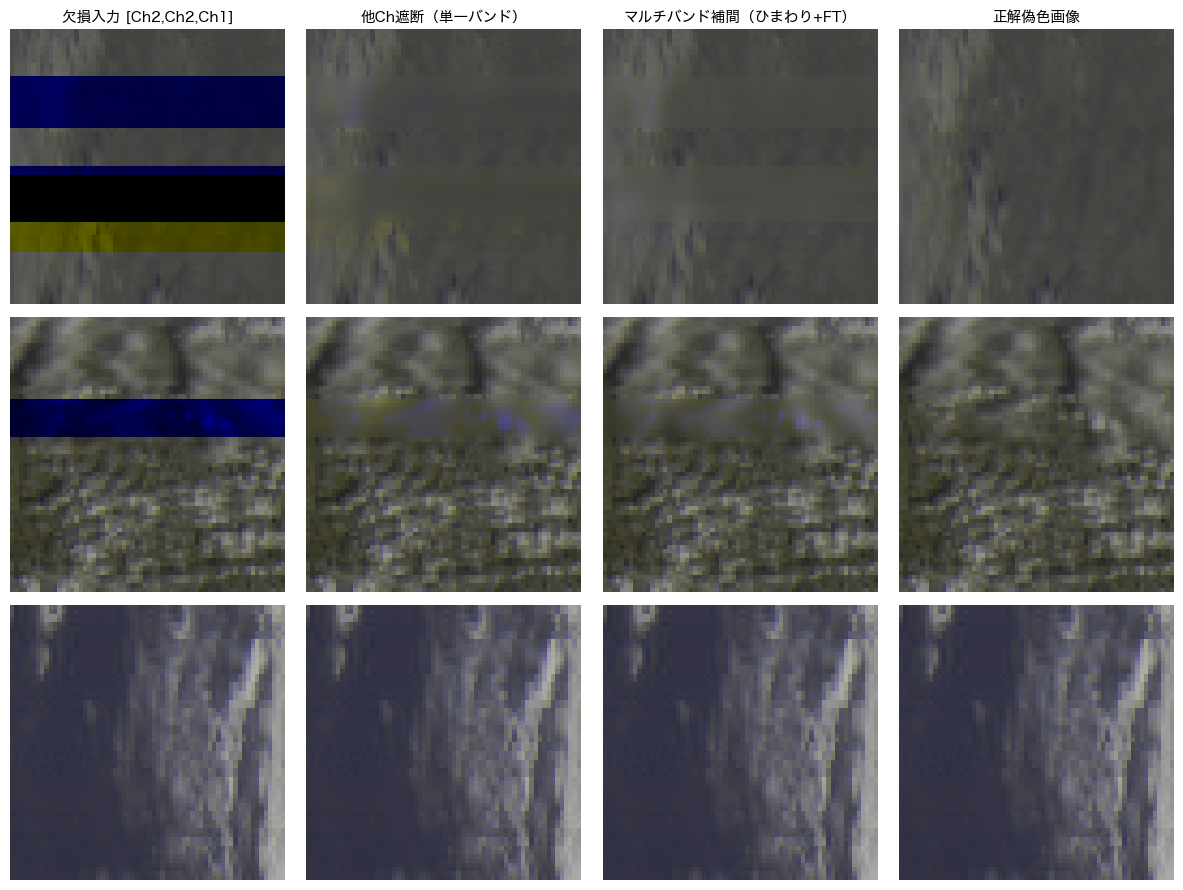

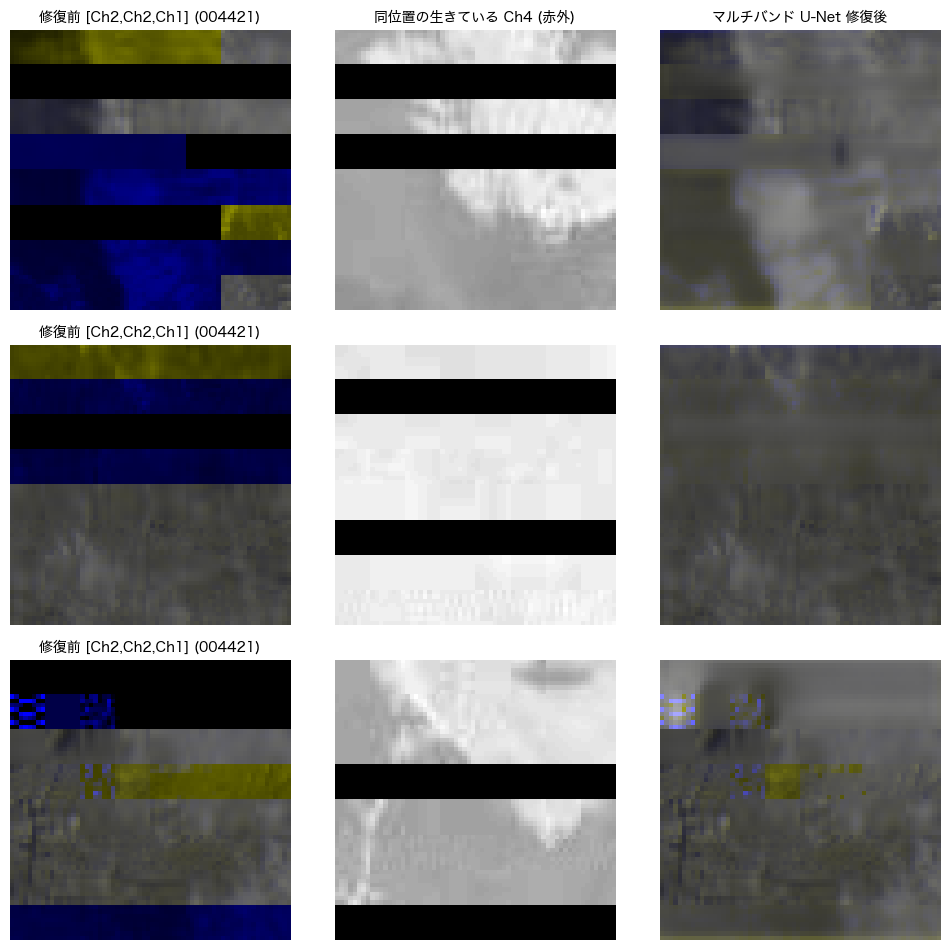

In [3]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

def to_pseudo_avhrr221(ch3_tensor: torch.Tensor) -> np.ndarray:
    # [Ch1, Ch2, Ch4] -> RGB=[Ch2, Ch2, Ch1]
    arr = ch3_tensor.detach().cpu().numpy()
    rgb = np.stack([arr[1], arr[1], arr[0]], axis=-1)
    return np.clip(rgb, 0.0, 1.0)

def reconstruct_isolated(model, corr, omask):
    out = torch.zeros_like(corr)
    for c_idx in range(3):
        cc = torch.zeros_like(corr)
        cm = torch.zeros_like(omask)
        cc[:, c_idx] = corr[:, c_idx]
        cm[:, c_idx] = omask[:, c_idx]
        out[:, c_idx] = model(cc, cm)[:, c_idx]
    return out

val_ds = IndependentBandStripeDataset(meteor_val_patches, fixed_seed=2026)
sample_indices = np.linspace(0, len(val_ds) - 1, min(3, len(val_ds)), dtype=int)

fig, axes = plt.subplots(len(sample_indices), 4, figsize=(12, 3.0 * len(sample_indices)))
pre_mb.eval()
with torch.no_grad():
    for r_idx, s_idx in enumerate(sample_indices):
        corr, omask, _, cln = val_ds[int(s_idx)]
        bc = corr.unsqueeze(0).to(device)
        bm = omask.unsqueeze(0).to(device)
        pred_iso = reconstruct_isolated(pre_mb, bc, bm).squeeze(0).cpu()
        pred_mb = pre_mb(bc, bm).squeeze(0).cpu()

        for c_idx, (t_img, title) in enumerate([
            (to_pseudo_avhrr221(corr), "欠損入力 [Ch2,Ch2,Ch1]"),
            (to_pseudo_avhrr221(pred_iso), "他Ch遮断（単一バンド）"),
            (to_pseudo_avhrr221(pred_mb), "マルチバンド補間（ひまわり+FT）"),
            (to_pseudo_avhrr221(cln), "正解偽色画像"),
        ]):
            ax = axes[r_idx, c_idx]
            ax.imshow(t_img)
            if r_idx == 0:
                ax.set_title(title, fontsize=10.5)
            ax.axis("off")

plt.tight_layout()
plt.show()

# --- 実測パスの「本物の一部バンド欠損」領域の修復デモ ---
real_mb_samples = []
for pid in ["METEOR-M2 3_20261103_004421", "METEOR-M2 3_20261026_003009"]:
    arr_r = load_meteor_3band(pid)
    h, w, _ = arr_r.shape
    used_x = []
    for y in range(0, h - 64 + 1, 16):
        for x in range(160, w - 160 - 64 + 1, 48):
            if any(abs(x - ux) < 96 for ux in used_x):
                continue
            crop = arr_r[y:y + 64, x:x + 64]
            m12 = (crop[..., :2] > 0.02)
            m_all = (crop > 0.02)
            # Ch1 または Ch2 に 10〜55% の欠損があり、かつ他バンドが補完できている箇所を抽出
            partial_ratio = (m_all.any(axis=2) & (~m_all.all(axis=2))).mean()
            if 0.12 <= partial_ratio <= 0.65 and m12.mean() < 0.90 and crop[..., 2].mean() > 0.08:
                real_mb_samples.append((pid, crop, m_all.astype(np.float32)))
                used_x.append(x)
                break
        if len(real_mb_samples) >= 3:
            break
    if len(real_mb_samples) >= 3:
        break

fig, axes = plt.subplots(len(real_mb_samples), 3, figsize=(10, 3.2 * len(real_mb_samples)))
if len(real_mb_samples) == 1:
    axes = np.array([axes])

with torch.no_grad():
    for r_idx, (pid, crop, vmask) in enumerate(real_mb_samples):
        t_in = torch.from_numpy(crop.transpose(2, 0, 1)).unsqueeze(0).to(device)
        t_mk = torch.from_numpy(vmask.transpose(2, 0, 1)).unsqueeze(0).to(device)
        repaired = pre_mb(t_in, t_mk).squeeze(0).cpu()

        raw_rgb = to_pseudo_avhrr221(torch.from_numpy(crop.transpose(2, 0, 1)))
        guide_ch4 = crop[..., 2]
        rep_rgb = to_pseudo_avhrr221(repaired)

        for c_idx, (img_s, title) in enumerate([
            (raw_rgb, f"修復前 [Ch2,Ch2,Ch1] ({pid.split('_')[-1]})"),
            (guide_ch4, "同位置の生きている Ch4 (赤外)"),
            (rep_rgb, "マルチバンド U-Net 修復後"),
        ]):
            ax = axes[r_idx, c_idx]
            ax.imshow(img_s, cmap="gray" if img_s.ndim == 2 else None)
            if r_idx == 0 or c_idx == 0:
                ax.set_title(title, fontsize=10)
            ax.axis("off")

plt.tight_layout()
plt.show()

## 4. 共通ベンチマーク評価：ベスト実測画像（`METEOR-M2 3_20261026_003009`, `1568×792`）全体への適用デモ

共通指標（`Benchmark Hole L1`, `Hole PSNR [dB]`, `Vertical Seam Jump L1`）を算出したうえで、ベスト実測パス `1568×792` の全 3 バンド（`MSU-MR-1`, `MSU-MR-2`, `MSU-MR-4`）に対してマルチバンド U-Net のタイリング推論を実行し、片バンド生存領域の救済＋近傍欠損修復を行ったフル画像を可視化します。

[04 共通ベンチマーク (未知領域 10/26 48枚)]
  1. 他Ch遮断(単一バンド相当) -> Hole L1: 0.0394 | Hole PSNR: 24.18 dB
  2. マルチバンド(事前学習なし) -> Hole L1: 0.0381 | Hole PSNR: 25.58 dB
  3. マルチバンド(ひまわり+FT)  -> Hole L1: 0.0270 | Hole PSNR: 28.17 dB
フル画像有効領域 (RGB生存): Before(Ch1&2): 33.0% -> AnyCh救済+16px近傍: 79.8%
Vertical Seam Jump L1 -> Before: 0.0155 | Local Repair: 0.0137 | Full Repair: 0.0112


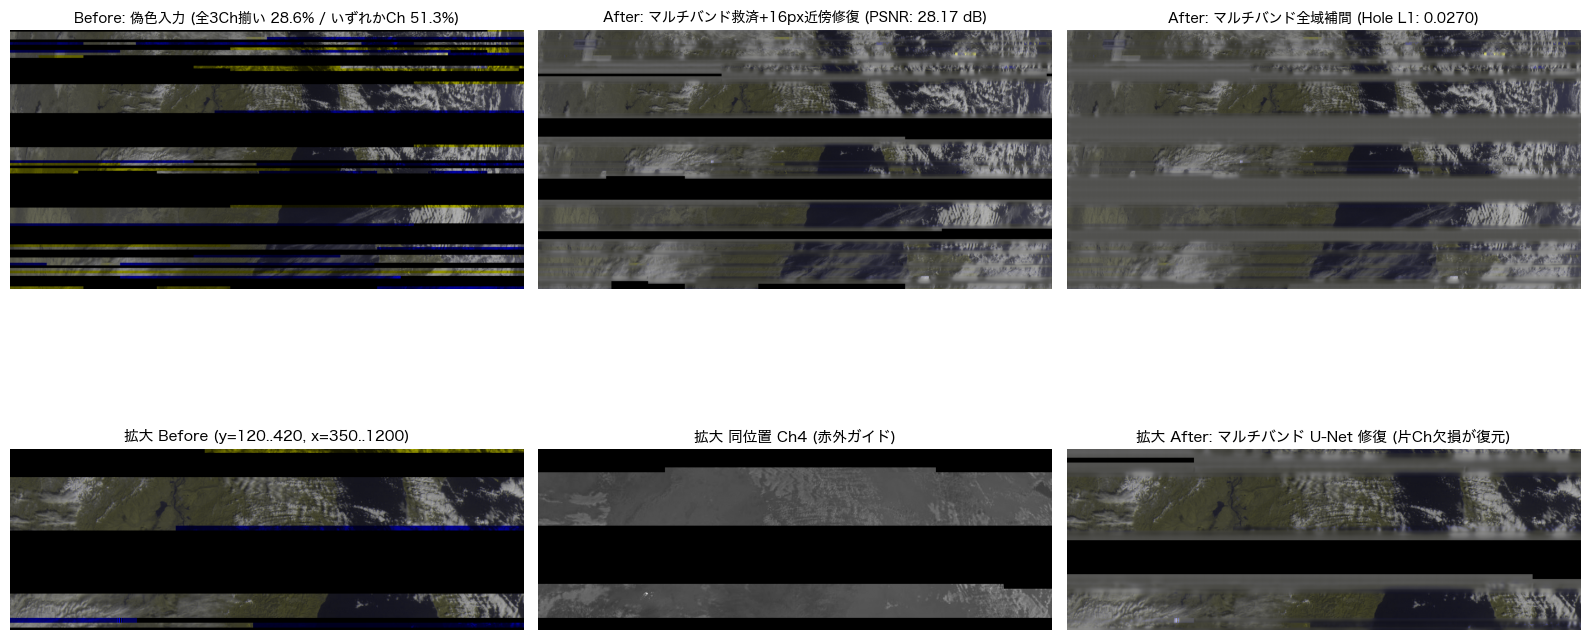

In [4]:
# 日本語フォント設定（セル冒頭で必須）
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    import japanize_matplotlib  # noqa: F401
except ImportError:
    pass

_available_fonts = {f.name for f in fm.fontManager.ttflist}
_jp_fonts = [f for f in ["IPAexGothic", "Hiragino Sans", "DejaVu Sans"] if f in _available_fonts]
plt.rcParams["font.family"] = _jp_fonts or ["DejaVu Sans"]
plt.rcParams["mathtext.fontset"] = "stix"
plt.rcParams["axes.unicode_minus"] = False

from scipy.ndimage import binary_dilation

def compute_mb_hole_metrics(net, loader, isolate_bands: bool = False):
    net.eval()
    abs_sum, sq_sum, px_sum = 0.0, 0.0, 0.0
    with torch.no_grad():
        for corr, omask, hmask, cln in loader:
            corr, omask, hmask, cln = corr.to(device), omask.to(device), hmask.to(device), cln.to(device)
            if not isolate_bands:
                out = net(corr, omask)
                diff = out - cln
                abs_sum += (torch.abs(diff) * hmask).sum().item()
                sq_sum += ((diff ** 2) * hmask).sum().item()
                px_sum += hmask.sum().item()
            else:
                for c_idx in range(3):
                    cc = torch.zeros_like(corr)
                    cm = torch.zeros_like(omask)
                    cc[:, c_idx] = corr[:, c_idx]
                    cm[:, c_idx] = omask[:, c_idx]
                    out_c = net(cc, cm)
                    diff_c = out_c[:, c_idx] - cln[:, c_idx]
                    hm_c = hmask[:, c_idx]
                    abs_sum += (torch.abs(diff_c) * hm_c).sum().item()
                    sq_sum += ((diff_c ** 2) * hm_c).sum().item()
                    px_sum += hm_c.sum().item()
    l1 = abs_sum / max(px_sum, 1e-6)
    mse = sq_sum / max(px_sum, 1e-6)
    psnr = -10.0 * np.log10(max(mse, 1e-12))
    return l1, psnr

def inpaint_multiband_tiled(net, img_hw3: np.ndarray, mask_hw3: np.ndarray, patch_size=64, stride=32, batch_size=128):
    h, w, c = img_hw3.shape
    ys = list(range(0, h - patch_size + 1, stride))
    if ys[-1] != h - patch_size:
        ys.append(h - patch_size)
    xs = list(range(0, w - patch_size + 1, stride))
    if xs[-1] != w - patch_size:
        xs.append(w - patch_size)

    win_1d = np.hanning(patch_size + 4)[2:-2].astype(np.float32)
    win_2d = np.maximum(np.outer(win_1d, win_1d), 0.05)
    coords = [(y, x) for y in ys for x in xs]

    acc = np.zeros((h, w, c), dtype=np.float32)
    wsum = np.zeros((h, w, 1), dtype=np.float32)
    net.eval()
    with torch.no_grad():
        for i in range(0, len(coords), batch_size):
            batch_coords = coords[i:i + batch_size]
            b_img = np.stack([img_hw3[y:y + patch_size, x:x + patch_size].transpose(2, 0, 1) for y, x in batch_coords])
            b_msk = np.stack([mask_hw3[y:y + patch_size, x:x + patch_size].transpose(2, 0, 1) for y, x in batch_coords])
            pred = net(torch.from_numpy(b_img).to(device), torch.from_numpy(b_msk).to(device)).cpu().numpy()
            for idx, (y, x) in enumerate(batch_coords):
                acc[y:y + patch_size, x:x + patch_size] += pred[idx].transpose(1, 2, 0) * win_2d[..., None]
                wsum[y:y + patch_size, x:x + patch_size] += win_2d[..., None]

    merged = np.clip(acc / np.maximum(wsum, 1e-6), 0.0, 1.0)
    return img_hw3 * mask_hw3 + merged * (1.0 - mask_hw3)

l1_iso, psnr_iso = compute_mb_hole_metrics(pre_mb, val_loader, isolate_bands=True)
l1_scr, psnr_scr = compute_mb_hole_metrics(scratch_mb, val_loader, isolate_bands=False)
l1_mb, psnr_mb = compute_mb_hole_metrics(pre_mb, val_loader, isolate_bands=False)

mask_hw3 = (arr_1026 > 0.02).astype(np.float32)
any_valid_2d = mask_hw3.max(axis=2) > 0.5
all_valid_2d = mask_hw3.min(axis=2) > 0.5
near_any_mask = binary_dilation(any_valid_2d, structure=np.ones((33, 1), dtype=bool))[..., None].astype(np.float32)

repaired_3ch_full = inpaint_multiband_tiled(pre_mb, arr_1026, mask_hw3)
# 実用モード: いずれかのバンドが生存している領域 + その上下16px近傍のみを修復
repaired_3ch_local = arr_1026 * mask_hw3 + repaired_3ch_full * (1.0 - mask_hw3) * near_any_mask

def arr_to_avhrr(arr_hw3: np.ndarray) -> np.ndarray:
    return np.clip(np.stack([arr_hw3[..., 1], arr_hw3[..., 1], arr_hw3[..., 0]], axis=-1), 0.0, 1.0)

before_rgb = arr_to_avhrr(arr_1026)
local_rgb = arr_to_avhrr(repaired_3ch_local)
full_rgb = arr_to_avhrr(repaired_3ch_full)

def seam_jump(arr):
    return float(np.abs(arr[1:] - arr[:-1]).mean())

print(f"[04 共通ベンチマーク (未知領域 10/26 48枚)]")
print(f"  1. 他Ch遮断(単一バンド相当) -> Hole L1: {l1_iso:.4f} | Hole PSNR: {psnr_iso:.2f} dB")
print(f"  2. マルチバンド(事前学習なし) -> Hole L1: {l1_scr:.4f} | Hole PSNR: {psnr_scr:.2f} dB")
print(f"  3. マルチバンド(ひまわり+FT)  -> Hole L1: {l1_mb:.4f} | Hole PSNR: {psnr_mb:.2f} dB")
print(f"フル画像有効領域 (RGB生存): Before(Ch1&2): {((mask_hw3[...,0]>0.5)&(mask_hw3[...,1]>0.5)).mean()*100:.1f}% -> AnyCh救済+16px近傍: {(local_rgb.max(axis=2)>0.02).mean()*100:.1f}%")
print(f"Vertical Seam Jump L1 -> Before: {seam_jump(before_rgb):.4f} | Local Repair: {seam_jump(local_rgb):.4f} | Full Repair: {seam_jump(full_rgb):.4f}")

y0, y1, x0, x1 = 120, 420, 350, 1200
fig, axes = plt.subplots(2, 3, figsize=(16, 9.2))
axes[0, 0].imshow(before_rgb)
axes[0, 0].set_title(f"Before: 偽色入力 (全3Ch揃い {all_valid_2d.mean()*100:.1f}% / いずれかCh {any_valid_2d.mean()*100:.1f}%)", fontsize=10)
axes[0, 0].axis("off")

axes[0, 1].imshow(local_rgb)
axes[0, 1].set_title(f"After: マルチバンド救済+16px近傍修復 (PSNR: {psnr_mb:.2f} dB)", fontsize=10)
axes[0, 1].axis("off")

axes[0, 2].imshow(full_rgb)
axes[0, 2].set_title(f"After: マルチバンド全域補間 (Hole L1: {l1_mb:.4f})", fontsize=10)
axes[0, 2].axis("off")

axes[1, 0].imshow(before_rgb[y0:y1, x0:x1])
axes[1, 0].set_title(f"拡大 Before (y={y0}..{y1}, x={x0}..{x1})", fontsize=10.5)
axes[1, 0].axis("off")

axes[1, 1].imshow(arr_1026[y0:y1, x0:x1, 2], cmap="gray")
axes[1, 1].set_title("拡大 同位置 Ch4 (赤外ガイド)", fontsize=10.5)
axes[1, 1].axis("off")

axes[1, 2].imshow(local_rgb[y0:y1, x0:x1])
axes[1, 2].set_title("拡大 After: マルチバンド U-Net 修復 (片Ch欠損が復元)", fontsize=10.5)
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()